# Retail Sales Data Analysis with AI-Assisted Customer Segmentation
**Student:** Manish Singh Bisht  
**Project:** AICTE | IBM SkillsBuild Data Analytics with AI Internship

## Project overview
This notebook explores retail transactions, calculates sales KPIs, visualizes patterns, and uses K-Means clustering to group customers by purchasing behavior.

**Dataset:** Retail Sales Data Set (public GitHub dataset). If the download link is unavailable, download the CSV manually and place it beside this notebook as `Retail Sales Data Set.csv`.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from pathlib import Path

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")
print("Libraries imported successfully.")

Libraries imported successfully.


## 1. Load the dataset
The notebook first tries the public CSV URL. If that fails, it looks for a local CSV file in this project folder.

In [2]:
DATA_URL = "https://raw.githubusercontent.com/Seunfunmee/Retail-Sales-Data-Set/main/Retail%20Sales%20Data%20Set.csv"
LOCAL_CSV = Path("Retail Sales Data Set.csv")

try:
    df = pd.read_csv(DATA_URL)
    print("Dataset loaded from the public URL.")
except Exception as error:
    if LOCAL_CSV.exists():
        df = pd.read_csv(LOCAL_CSV)
        print("Dataset loaded from the local CSV file.")
    else:
        raise RuntimeError(
            "Could not download the dataset and no local CSV was found. "
            "Download the dataset CSV, save it as 'Retail Sales Data Set.csv' "
            "in the same folder as this notebook, then run this cell again."
        ) from error

print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded from the public URL.
Dataset shape: (1000, 24)


,Transaction ID,Date,Gender,Age,Age Group,Product Category,Quantity,Price per Unit,Total Amount,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16,Min_age,Max_age,Avg_age,Total Sales Revenue,Average Order value,Category,Sales
0,1,11/24/2023,Male,34,Middle Age,Beauty,3,50,150,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.0,64.0,41.0,456000.0,456.0,Electronics,156905.0
1,2,2/27/2023,Female,26,Adolescent,Clothing,2,500,1000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Clothing,155580.0
2,3,1/13/2023,Male,50,Middle Age,Electronics,1,30,30,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Beauty,143515.0
3,4,5/21/2023,Male,37,Middle Age,Clothing,1,500,500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,5/6/2023,Male,30,Adolescent,Beauty,2,50,100,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Inspect and clean the data
We standardize column names, convert dates and numeric fields, and remove duplicate or incomplete records where essential fields are missing.

In [3]:
print("Original columns:", df.columns.tolist())
df.columns = (
    df.columns.astype(str).str.strip().str.lower()
      .str.replace(r"[^a-z0-9]+", "_", regex=True)
      .str.strip("_")
)
print("Standardized columns:", df.columns.tolist())
display(df.info())
display(df.isna().sum().to_frame("missing_values"))
print("Duplicate rows:", df.duplicated().sum())

Original columns: ['Transaction ID', 'Date', 'Gender', 'Age', 'Age Group', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12', 'Unnamed: 13', 'Unnamed: 14', 'Unnamed: 15', 'Unnamed: 16', 'Min_age', 'Max_age', 'Avg_age', 'Total Sales Revenue', 'Average Order value', ' Category', 'Sales']
Standardized columns: ['transaction_id', 'date', 'gender', 'age', 'age_group', 'product_category', 'quantity', 'price_per_unit', 'total_amount', 'unnamed_9', 'unnamed_10', 'unnamed_11', 'unnamed_12', 'unnamed_13', 'unnamed_14', 'unnamed_15', 'unnamed_16', 'min_age', 'max_age', 'avg_age', 'total_sales_revenue', 'average_order_value', 'category', 'sales']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 24 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   transaction_id       1000 non-null   int64  
 1   date                 1

None

,missing_values
transaction_id,0
date,0
gender,0
age,0
age_group,0
product_category,0
quantity,0
price_per_unit,0
total_amount,0
unnamed_9,1000


Duplicate rows: 0


In [7]:
# Rename common dataset columns to consistent names when present
rename_map = {
    "transaction_id": "transaction_id",
    "date": "date",
    "customer_id": "customer_id",
    "gender": "gender",
    "age": "age",
    "product_category": "product_category",
    "quantity": "quantity",
    "price_per_unit": "price_per_unit",
    "total_amount": "total_amount"
}
df = df.rename(columns={c: rename_map[c] for c in df.columns if c in rename_map})

required = ["date", "gender", "age", "product_category", "quantity", "price_per_unit", "total_amount"]
missing_required = [c for c in required if c not in df.columns]
if missing_required:
    raise ValueError(f"Expected columns not found: {missing_required}. Please check the dataset column names.")

df["date"] = pd.to_datetime(df["date"], errors="coerce")
for col in ["age", "quantity", "price_per_unit", "total_amount"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

before = len(df)
df = df.drop_duplicates()
df = df.dropna(subset=["date", "gender", "age", "product_category", "quantity", "total_amount"])
df = df[df["quantity"] > 0]
df = df[df["total_amount"] >= 0]
print(f"Rows before cleaning: {before:,}")
print(f"Rows after cleaning:  {len(df):,}")
display(df.head())

Rows before cleaning: 1,000
Rows after cleaning:  1,000


,transaction_id,date,gender,age,age_group,product_category,quantity,price_per_unit,total_amount,unnamed_9,unnamed_10,unnamed_11,unnamed_12,unnamed_13,unnamed_14,unnamed_15,unnamed_16,min_age,max_age,avg_age,total_sales_revenue,average_order_value,category,sales
0,1,2023-11-24,Male,34,Middle Age,Beauty,3,50,150,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.0,64.0,41.0,456000.0,456.0,Electronics,156905.0
1,2,2023-02-27,Female,26,Adolescent,Clothing,2,500,1000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Clothing,155580.0
2,3,2023-01-13,Male,50,Middle Age,Electronics,1,30,30,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Beauty,143515.0
3,4,2023-05-21,Male,37,Middle Age,Clothing,1,500,500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,2023-05-06,Male,30,Adolescent,Beauty,2,50,100,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Feature engineering
Create useful time and age-group fields for analysis.

In [8]:
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.to_period("M").astype(str)
df["month_name"] = df["date"].dt.strftime("%b")
if "age" in df.columns:
    df["age_group"] = pd.cut(
        df["age"],
        bins=[0, 17, 25, 35, 45, 55, 120],
        labels=["Under 18", "18–25", "26–35", "36–45", "46–55", "56+"],
        include_lowest=True
    )
print("Feature engineering complete.")
display(df.head())

Feature engineering complete.


,transaction_id,date,gender,age,age_group,product_category,quantity,price_per_unit,total_amount,unnamed_9,unnamed_10,unnamed_11,unnamed_12,unnamed_13,unnamed_14,unnamed_15,unnamed_16,min_age,max_age,avg_age,total_sales_revenue,average_order_value,category,sales,year,month,month_name
0,1,2023-11-24,Male,34,26–35,Beauty,3,50,150,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.0,64.0,41.0,456000.0,456.0,Electronics,156905.0,2023,2023-11,Nov
1,2,2023-02-27,Female,26,26–35,Clothing,2,500,1000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Clothing,155580.0,2023,2023-02,Feb
2,3,2023-01-13,Male,50,46–55,Electronics,1,30,30,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Beauty,143515.0,2023,2023-01,Jan
3,4,2023-05-21,Male,37,36–45,Clothing,1,500,500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2023,2023-05,May
4,5,2023-05-06,Male,30,26–35,Beauty,2,50,100,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2023,2023-05,May


## 4. Key performance indicators (KPIs)

In [11]:

total_revenue = df["total_amount"].sum()

transaction_count = df["transaction_id"].nunique()

total_quantity = df["quantity"].sum()

average_transaction_value = (
    total_revenue / transaction_count if transaction_count else 0
)

kpis = pd.DataFrame({
    "Metric": [
        "Total revenue",
        "Total transactions",
        "Units sold",
        "Average transaction value"
    ],
    "Value": [
        total_revenue,
        transaction_count,
        total_quantity,
        average_transaction_value
    ]
})

display(kpis.style.format({"Value": "{:,.2f}"}))

,Metric,Value
0,Total revenue,"456,000.00"
1,Total transactions,"1,000.00"
2,Units sold,"2,514.00"
3,Average transaction value,456.00


## 5. Sales by product category

,product_category,total_amount
2,Electronics,156905
1,Clothing,155580
0,Beauty,143515


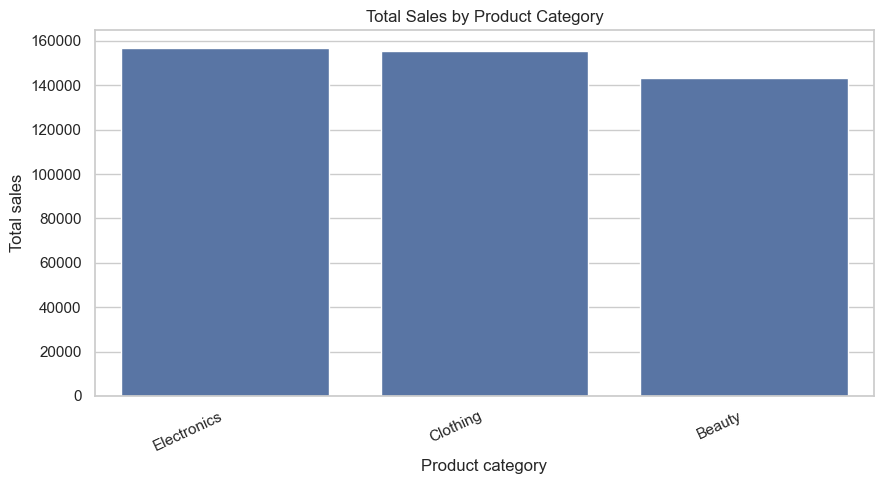

In [12]:
category_sales = df.groupby("product_category", as_index=False)["total_amount"].sum().sort_values("total_amount", ascending=False)
display(category_sales)
plt.figure(figsize=(9, 5))
sns.barplot(data=category_sales, x="product_category", y="total_amount")
plt.title("Total Sales by Product Category")
plt.xlabel("Product category")
plt.ylabel("Total sales")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

## 6. Monthly sales trend

,month,total_amount
0,2023-01,35450
1,2023-02,44060
2,2023-03,28990
3,2023-04,33870
4,2023-05,53150
5,2023-06,36715
6,2023-07,35465
7,2023-08,36960
8,2023-09,23620
9,2023-10,46580


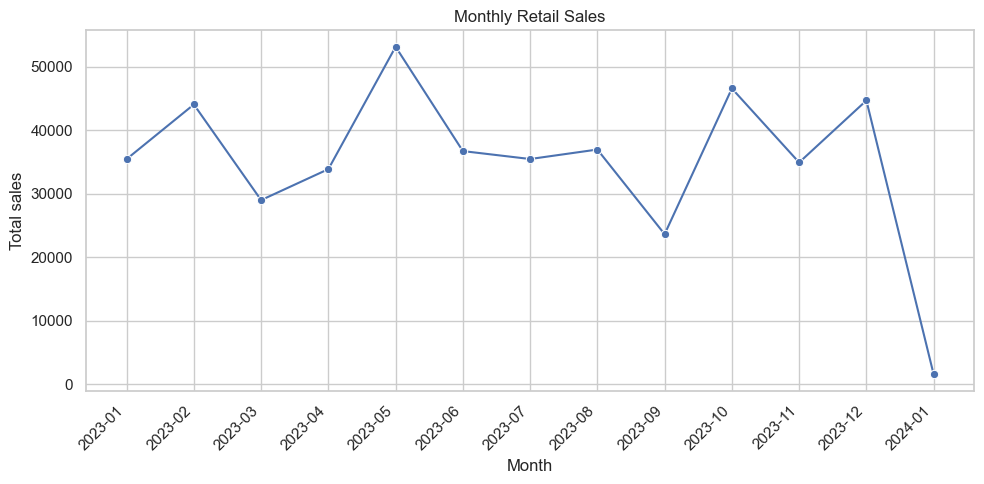

In [13]:
monthly_sales = df.groupby("month", as_index=False)["total_amount"].sum().sort_values("month")
display(monthly_sales)
plt.figure(figsize=(10, 5))
sns.lineplot(data=monthly_sales, x="month", y="total_amount", marker="o")
plt.title("Monthly Retail Sales")
plt.xlabel("Month")
plt.ylabel("Total sales")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 7. Customer and demographic analysis

,gender,total_amount
0,Female,232840
1,Male,223160


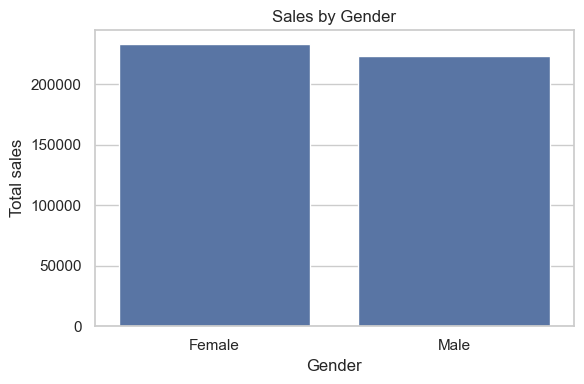

,age_group,total_amount
0,Under 18,0
1,18–25,84550
2,26–35,98480
3,36–45,91870
4,46–55,100690
5,56+,80410


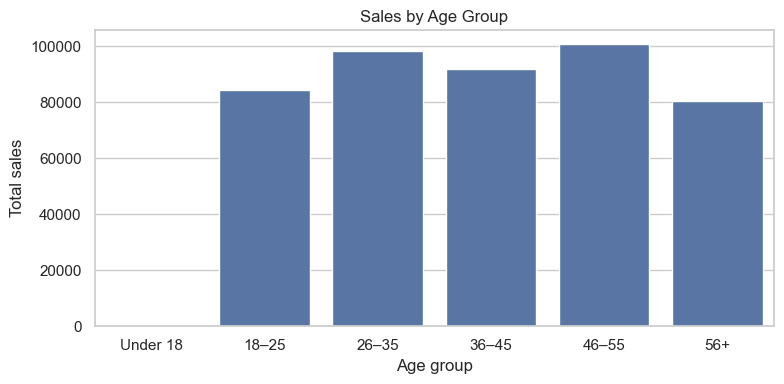

In [14]:
if "gender" in df.columns:
    gender_sales = df.groupby("gender", as_index=False)["total_amount"].sum().sort_values("total_amount", ascending=False)
    display(gender_sales)
    plt.figure(figsize=(6, 4))
    sns.barplot(data=gender_sales, x="gender", y="total_amount")
    plt.title("Sales by Gender")
    plt.xlabel("Gender")
    plt.ylabel("Total sales")
    plt.tight_layout()
    plt.show()

if "age_group" in df.columns:
    age_sales = df.groupby("age_group", observed=False, as_index=False)["total_amount"].sum()
    display(age_sales)
    plt.figure(figsize=(8, 4))
    sns.barplot(data=age_sales, x="age_group", y="total_amount")
    plt.title("Sales by Age Group")
    plt.xlabel("Age group")
    plt.ylabel("Total sales")
    plt.tight_layout()
    plt.show()

## 8. AI/ML: Customer segmentation with K-Means
For each customer, calculate spending and transaction behavior, scale the features, and cluster customers into three groups. These are exploratory segments; interpret them using the cluster summary rather than assuming labels in advance.

Average transaction characteristics by segment:


,transactions,average_age,total_revenue,average_transaction_value,units_sold
segment,,,,,
0,447,41.90,76855,171.94,641
1,289,41.75,36545,126.45,1027
2,264,40.14,342600,1297.73,846


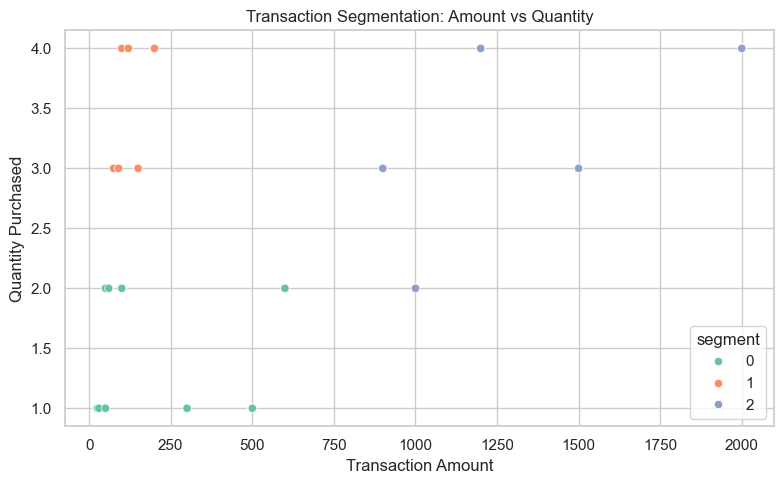

In [16]:

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Segment transactions using the available data
features = df[
    ["age", "quantity", "price_per_unit", "total_amount"]
].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(features)

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df["segment"] = kmeans.fit_predict(X_scaled)

# Summarize the transaction segments
segment_summary = df.groupby("segment").agg(
    transactions=("transaction_id", "count"),
    average_age=("age", "mean"),
    total_revenue=("total_amount", "sum"),
    average_transaction_value=("total_amount", "mean"),
    units_sold=("quantity", "sum")
).round(2)

print("Average transaction characteristics by segment:")
display(segment_summary)

# Visualize the segments
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="total_amount",
    y="quantity",
    hue="segment",
    palette="Set2"
)
plt.title("Transaction Segmentation: Amount vs Quantity")
plt.xlabel("Transaction Amount")
plt.ylabel("Quantity Purchased")
plt.tight_layout()
plt.show()

## 9. Correlation heatmap

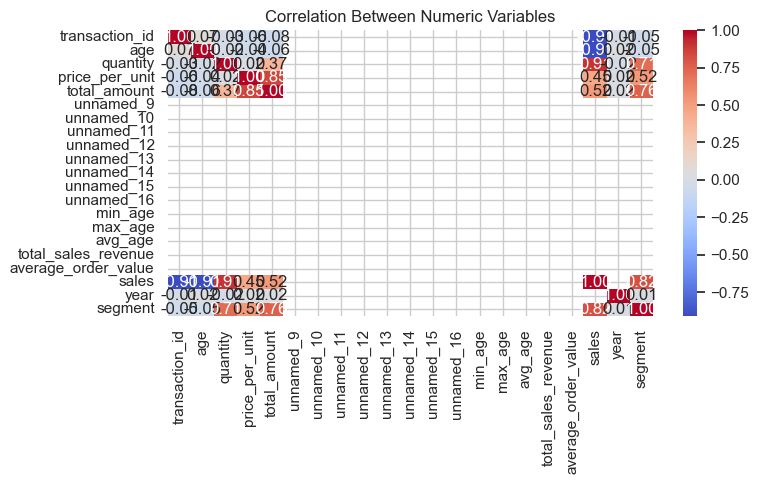

In [17]:
numeric_cols = df.select_dtypes(include=np.number)
if len(numeric_cols.columns) >= 2:
    plt.figure(figsize=(8, 5))
    sns.heatmap(numeric_cols.corr(), annot=True, cmap="coolwarm", fmt=".2f")
    plt.title("Correlation Between Numeric Variables")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough numeric columns for a correlation heatmap.")

## 10. Business insights and recommendations

Use the charts and tables above to identify which product categories and months generate the most revenue, and which customer segments have higher spending or purchase frequency.

Suggested recommendations:
1. Prioritize inventory and promotions for high-revenue product categories.
2. Investigate weaker months and test seasonal campaigns.
3. Tailor offers to customer groups based on observed spending and transaction frequency.
4. Repeat the analysis regularly to monitor changes over time.

**Important:** Base your final report's numerical claims on the actual outputs produced when you run this notebook. The K-Means clusters are exploratory and should be interpreted using their summary statistics.
